In [4]:
print("y_test exists:", 'y_test' in globals())
print("y_pred exists:", 'y_pred' in globals())

y_test exists: False
y_pred exists: False


In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score

X_train = pd.read_csv("X_train_filtered.csv")
X_test = pd.read_csv("X_test_filtered.csv")
y_train = pd.read_csv("y_train.csv").squeeze()
y_test = pd.read_csv("y_test.csv").squeeze()

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (364, 30)
X_test shape: (92, 30)
y_train shape: (364,)
y_test shape: (92,)


In [6]:
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import numpy as np

# Train Ridge Regression model
ridge_model = Ridge()
ridge_model.fit(X_train, y_train)

# Predict test values
y_pred = ridge_model.predict(X_test)

# Evaluate model
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

print("Model trained successfully!")

Mean Squared Error: 0.014543105241349209
R2 Score: 0.3161508735401125
Model trained successfully!


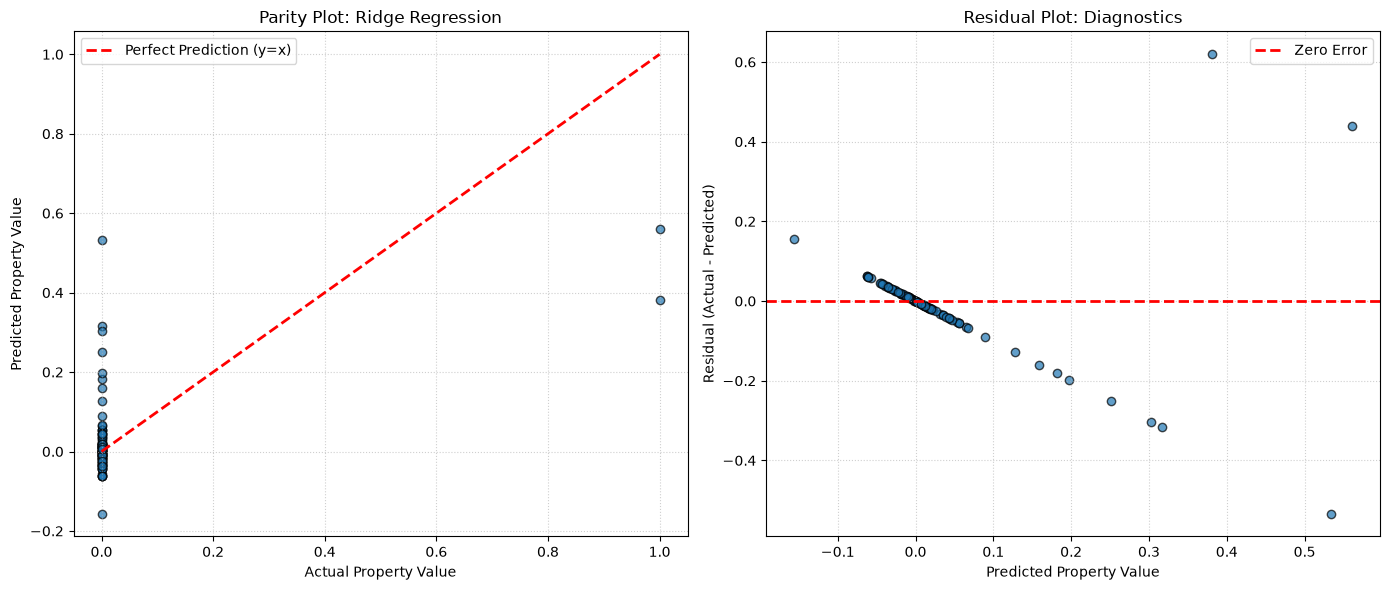

Diagnostic plots successfully rendered!


In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Calculate residuals
residuals = y_test - y_pred

# Create two plots
fig, ax = plt.subplots(1, 2, figsize=(14, 6))

# 1. Parity Plot
ax[0].scatter(y_test, y_pred, alpha=0.7, edgecolors='k')

ax[0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    lw=2,
    label='Perfect Prediction (y=x)'
)

ax[0].set_xlabel('Actual Property Value')
ax[0].set_ylabel('Predicted Property Value')
ax[0].set_title('Parity Plot: Ridge Regression')
ax[0].legend()
ax[0].grid(True, linestyle=':', alpha=0.6)

# 2. Residual Plot
ax[1].scatter(y_pred, residuals, alpha=0.7, edgecolors='k')

ax[1].axhline(
    0,
    color='r',
    linestyle='--',
    lw=2,
    label='Zero Error'
)

ax[1].set_xlabel('Predicted Property Value')
ax[1].set_ylabel('Residual (Actual - Predicted)')
ax[1].set_title('Residual Plot: Diagnostics')
ax[1].legend()
ax[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

print("Diagnostic plots successfully rendered!")